# Level 4 — Forcing, tori and phase

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/tutorials/worked-examples/04_forcing-tori-and-phase.ipynb)

Forced oscillators and maps on a torus: look at a periodically forced system
once per forcing period (a stroboscopic map), measure rotation numbers and
locking (Arnold tongues), iterate area-preserving and piecewise affine maps,
and reduce an oscillator to its phase (adjoint and interaction function). Each
model is written in Python with `ModelBuilder`, run by XPPAUT through
pyauto-xpp (`pyxpp`), and its numbers are checked against exact or published
values.

| | model | what it shows |
|---|---|---|
| [20](#forced-duffing) | forced Duffing oscillator | stroboscopic map, period doubling to chaos |
| [21](#forced-phase-oscillator) | forced phase oscillator | devil's staircase, Arnold tongues |
| [22](#phase-oscillators-table) | phase oscillators with a table | locking band from the tabulated coupling |
| [23](#chirikov-taylor-map) | standard (Chirikov–Taylor) map | invariant curves vs chaos, area preservation |
| [24](#piecewise-affine-map) | piecewise affine map | periods and islands at the golden mean |
| [25](#coupled-ginzburg-landau) | Ginzburg–Landau oscillator | adjoint, $H$ and $H_2$ against exact formulas |

**How to use this notebook.** Run the cells from the top (the first code cell
sets up helpers used by every section). Each section writes its model file to
`odes/<section>.ode` and its figures to `figures/<section>/`, and ends by
printing its checks. The last cell counts the checks of the whole notebook.

*Models 20–25 are based on examples from XPP Studio (Peter Ashwin and Bard
Ermentrout, GPL-3.0). Every number below is computed by XPPAUT and its AUTO
through pyauto-xpp.*

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.5.0

### Setup

`section(name)` starts a section: it sets `FIG` (the figure folder) and `ODE`
(the model file) and opens an empty list of checks. `check(what, value,
expected, tol)` compares a computed number with the expected one and records
the result; `checks_done()` prints the section's score.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyxpp.builder import ModelBuilder

HERE = Path.cwd()
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 12,
                     "legend.fontsize": 9, "savefig.dpi": 130})
results = {}


def section(name):
    """Start a section: its figure folder FIG, its model file ODE and an empty list of checks."""
    global NAME, FIG, ODE
    NAME = name
    FIG = HERE / "figures" / name
    FIG.mkdir(parents=True, exist_ok=True)
    ODE = HERE / "odes" / f"{name}.ode"
    ODE.parent.mkdir(exist_ok=True)
    results[name] = []


def check(what, value, expected, tol):
    ok = abs(value - expected) <= tol
    results[NAME].append(ok)
    print(f"  {'ok  ' if ok else 'FAIL'} {what}: {value:.6g} (expected {expected:.6g})")


def checks_done():
    r = results[NAME]
    print(f"\n{NAME}: {sum(r)}/{len(r)} checks passed")

<a id="forced-duffing"></a>
## 20. Forced Duffing oscillator: period doubling to chaos

A ball in a double well, with damping, shaken periodically:

$$
\dot x = y, \qquad \dot y = -d\,y - a\,x - b\,x^3 + f\cos(\omega t),
$$

with $a = -1$, $b = 1$ (two wells, at $x = \pm 1$), $d = 0.15$,
$\omega = 1.2$ and first $f = 0.3$. The right-hand side depends on time, so a
phase-plane picture with nullclines and a direction field means nothing here.
Instead we look once per forcing period $T = 2\pi/\omega$: a stroboscopic (or
Poincaré) section. A periodic response becomes a fixed point of this map
$P$, a response of period $2T$ two points, and chaos a fractal cloud.

We draw the section of the chaotic attractor at $f = 0.3$, the stroboscopic
bifurcation diagram in $f$, and find the first period doubling exactly from the
Floquet multipliers of the fixed point of $P$.

In [3]:
section("20_forced-duffing")

### The model

`STROBE` makes XPP take 200 RK4 steps per forcing period and store one point
per period, so `strobe` returns the attractor seen at $t = nT$.

In [4]:
mb = (ModelBuilder("forced_duffing")
      .comment("periodically forced double-well Duffing oscillator")
      .ode("x", "y")
      .ode("y", "-d*y-a*x-b*x^3+f*cos(om*t)")
      .parameter(d=0.15, a=-1, b=1, f=0.3, om=1.2)
      .initial(x=1, y=0)
      .option(total=200, dt=0.02, meth="rk4"))
print(mb.render())
m = mb.load(ODE)
d, om = 0.15, 1.2
T = 2 * np.pi / om
STROBE = dict(dt=T / 200, nout=200)


def strobe(f, x, y, periods, skip=0):
    tr = m.run(keep=False, f=f, x=x, y=y, total=(skip + periods) * T, trans=skip * T, **STROBE)
    return tr["x"], tr["y"]

# periodically forced double-well Duffing oscillator
x'=y
y'=-d*y-a*x-b*x^3+f*cos(om*t)
par d=0.15,a=-1,b=1,f=0.3,om=1.2
init x=1,y=0
@ total=200,dt=0.02,meth=rungekutta
done



### Stroboscopic section of the chaotic attractor at $f = 0.3$

4000 points, one per period, after a transient of 50 periods; in grey the flow
itself over 10 periods.

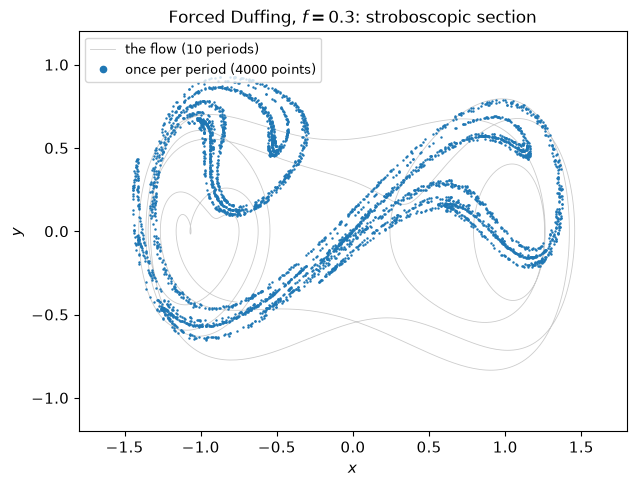

In [5]:
sx, sy = strobe(0.3, 1, 0, 4000, skip=50)
flow = m.run(keep=False, f=0.3, total=60 * T, trans=50 * T, dt=T / 200)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(flow["x"], flow["y"], color="0.8", lw=0.6, label="the flow (10 periods)")
ax.plot(sx, sy, ".", color="tab:blue", ms=1.5, label="once per period (4000 points)")
ax.set(xlim=(-1.8, 1.8), ylim=(-1.2, 1.2), xlabel="$x$", ylabel="$y$",
       title="Forced Duffing, $f = 0.3$: stroboscopic section")
ax.legend(loc="upper left", markerscale=6)
fig.tight_layout()
fig.savefig(FIG / "strobe_section.png")

### Stroboscopic bifurcation diagram in $f$

For each $f$, decreasing, record $x$ at $t = nT$ after a transient. Each run
starts where the previous one ended (at the same forcing phase), so the
diagram follows one attractor. A second, finer diagram zooms onto the
period-doubling cascade.

In [6]:
def diagram(F, x, y, skip, keep):
    pts = []
    for f in F:
        sx, sy = strobe(f, x, y, keep, skip)
        x, y = sx[-1], sy[-1]
        pts.append(sx[1:])
    return pts


F_all = np.linspace(0.45, 0.1, 351)
F_zoom = np.linspace(0.225, 0.185, 201)
D_all = diagram(F_all, 1.0, 0.0, 120, 80)
D_zoom = diagram(F_zoom, 0.5, 0.0, 400, 64)

### The stroboscopic map, its fixed point and Floquet multipliers

XPP stores trajectories in single precision, too coarse for finite differences
of $P$. So a second model carries the variational equations: the columns
$(u_1, v_1)$ and $(u_2, v_2)$ of the Jacobian $DP$ obey

$$
\dot u_k = v_k, \qquad \dot v_k = -d\,v_k - \bigl(a + 3b\,x^2\bigr)\,u_k, \qquad k = 1, 2,
$$

starting from the identity. Newton's method on $P(z) - z = 0$ gives the fixed
point $z$, and the eigenvalues of $DP(z)$ are its Floquet multipliers. A
bisection in $f$ then finds where the smallest multiplier passes through $-1$:
the first period doubling.

In [7]:
var = (ModelBuilder("forced_duffing_variational")
       .ode("x", "y").ode("y", "-d*y-a*x-b*x^3+f*cos(om*t)")
       .ode("u1", "v1").ode("v1", "-d*v1-(a+3*b*x^2)*u1")
       .ode("u2", "v2").ode("v2", "-d*v2-(a+3*b*x^2)*u2")
       .parameter(d=d, a=-1, b=1, f=0.3, om=om)
       .initial(x=1, y=0, u1=1, v1=0, u2=0, v2=1)
       .option(total=T, dt=T / 400, meth="rk4"))
mv = var.load(ODE.with_name(f"{NAME}_variational.ode"))


def P_and_DP(f, z):
    tr = mv.run(keep=False, f=f, x=z[0], y=z[1], total=T, dt=T / 400)
    e = {k: tr[k][-1] for k in ("x", "y", "u1", "v1", "u2", "v2")}
    return np.array([e["x"], e["y"]]), np.array([[e["u1"], e["u2"]], [e["v1"], e["v2"]]])


def multipliers(f, z):
    for _ in range(8):
        Pz, J = P_and_DP(f, z)
        z = z + np.linalg.solve(J - np.eye(2), z - Pz)
    return z, np.linalg.eigvals(P_and_DP(f, z)[1])


def fixed_point(f, z):
    return multipliers(f, z)[0]


z = np.array(strobe(0.18, 0.4, 0, 1, skip=300))[:, -1]
f_lo, f_hi = 0.18, 0.215
for _ in range(30):
    fm = (f_lo + f_hi) / 2
    zm, mu = multipliers(fm, z)
    if np.real(mu).min() > -1:
        f_lo, z = fm, zm
    else:
        f_hi = fm
f_pd = (f_lo + f_hi) / 2
z_pd, mu_pd = multipliers(f_pd, z)
print(f"first period doubling at f = {f_pd:.6f}: fixed point {np.round(z_pd, 5)}, "
      f"multipliers {np.round(np.real(mu_pd), 6)}")

first period doubling at f = 0.195829: fixed point [0.34945 0.19334], multipliers [-0.455938 -1.      ]


The two diagrams, with the doubling found from the multipliers marked on the
zoom.

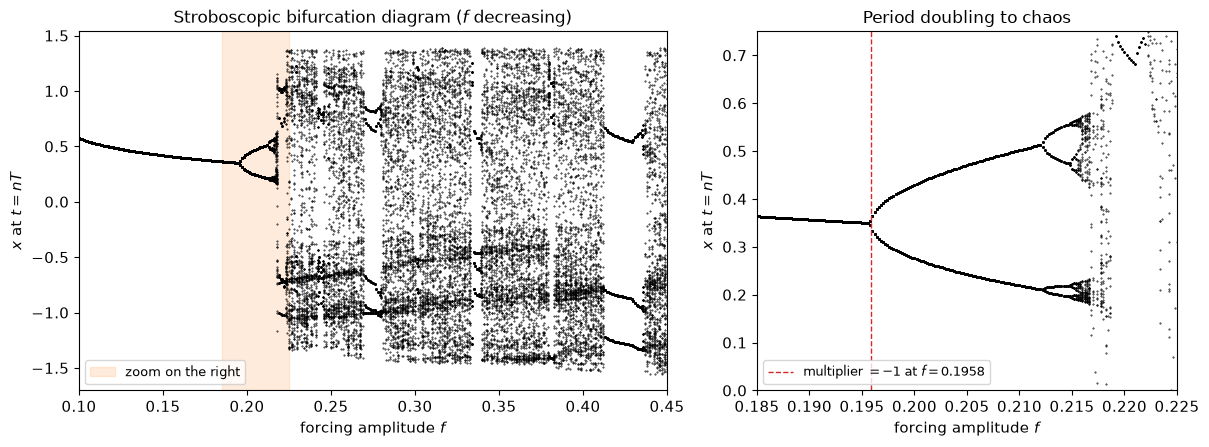

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
for ax, F, D in ((a1, F_all, D_all), (a2, F_zoom, D_zoom)):
    for f, xs in zip(F, D):
        ax.plot(np.full(len(xs), f), xs, ".", color="k", ms=0.8)
    ax.set(xlabel="forcing amplitude $f$", ylabel="$x$ at $t = nT$", xlim=(F.min(), F.max()))
a1.axvspan(F_zoom.min(), F_zoom.max(), color="tab:orange", alpha=0.15, label="zoom on the right")
a1.legend(loc="lower left")
a1.set_title("Stroboscopic bifurcation diagram ($f$ decreasing)")
a2.axvline(f_pd, color="tab:red", lw=1, ls="--", label=f"multiplier $= -1$ at $f = {f_pd:.4f}$")
a2.set(ylim=(0, 0.75), title="Period doubling to chaos")
a2.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "bifurcation_diagram.png")

### Checks

* **Liouville.** The divergence of the vector field is $-d$, so $P$ shrinks
  areas by exactly $e^{-dT}$: $\det DP = e^{-dT}$ at every point, and the
  product of the two Floquet multipliers is $e^{-dT}$. At the doubling one
  multiplier is $-1$, so the other is $-e^{-dT}$.
* **Weak forcing.** Near the bottom of the well $x = 1$, $\xi = x - 1$ obeys
  (the linearised spring is $-(a + 3b) = 2$)

$$
\ddot\xi + d\,\dot\xi + 2\,\xi = f\cos(\omega t),
$$

  so $\xi = A\cos(\omega t - \varphi)$ with

$$
A = \frac{f}{\sqrt{(2 - \omega^2)^2 + (d\omega)^2}}, \qquad \tan\varphi = \frac{d\omega}{2 - \omega^2},
$$

  and at $t = nT$: $\xi = A\cos\varphi$, $\dot\xi = A\omega\sin\varphi$. We
  check this at $f = 10^{-3}$, where the neglected terms are
  $O(A^2) \approx 3\times10^{-6}$.
* **The diagram.** Just above a supercritical doubling the two strobe points
  split by $s \sim \sqrt{f - f_{\mathrm{PD}}}$, so $s^2$ is linear in $f$ and
  vanishes at $f_{\mathrm{PD}}$; a straight-line fit to $s^2$ from the zoomed
  diagram must give the Floquet doubling to within one grid step. (Counting
  points fails: next to $f_{\mathrm{PD}}$ the multiplier is near $-1$ and the
  approach to the fixed point alternates for thousands of periods.)

In [9]:
check("det of the strobe map's Jacobian = exp(-d T) (exact)",
      np.linalg.det(P_and_DP(0.3, np.array([0.5, 0.2]))[1]), np.exp(-d * T), 1e-6)
check("product of Floquet multipliers at the doubling = exp(-d T)", np.real(np.prod(mu_pd)), np.exp(-d * T), 1e-6)
check("other multiplier at the doubling = -exp(-d T)", np.real(mu_pd).max(), -np.exp(-d * T), 1e-4)
fs = 1e-3
A, phi = fs / np.hypot(2 - om**2, d * om), np.arctan2(d * om, 2 - om**2)
z_lin = fixed_point(fs, np.array([1.0, 0.0]))
check("weak forcing: strobe x - 1 vs linear theory", z_lin[0] - 1, A * np.cos(phi), 1e-5)
check("weak forcing: strobe y vs linear theory", z_lin[1], A * om * np.sin(phi), 1e-5)
split = np.array([abs(xs[-1] - xs[-2]) for xs in D_zoom])
near = (split > 0.02) & (F_zoom < f_pd + 0.006)
slope, icpt = np.polyfit(F_zoom[near], split[near] ** 2, 1)
check("diagram: zero of the split^2 fit vs Floquet doubling", -icpt / slope, f_pd, F_zoom[0] - F_zoom[1])
checks_done()

  ok   det of the strobe map's Jacobian = exp(-d T) (exact): 0.455938 (expected 0.455938)
  ok   product of Floquet multipliers at the doubling = exp(-d T): 0.455938 (expected 0.455938)
  ok   other multiplier at the doubling = -exp(-d T): -0.455938 (expected -0.455938)


  ok   weak forcing: strobe x - 1 vs linear theory: 0.00161731 (expected 0.0016185)
  ok   weak forcing: strobe y vs linear theory: 0.000625711 (expected 0.000624277)
  ok   diagram: zero of the split^2 fit vs Floquet doubling: 0.195822 (expected 0.195829)

20_forced-duffing: 6/6 checks passed


<a id="forced-phase-oscillator"></a>
## 21. Forced phase oscillator: devil's staircase and Arnold tongues

$x$ is the phase of an oscillator with natural frequency 1, $y$ the phase of a
periodic forcing with frequency $\omega$:

$$
\dot x = 1 + b\,p(x)\cos y, \qquad \dot y = \omega, \qquad p(x) = -\frac{\sin x}{1 + a\cos x},
$$

with $a = 0.25$. The function $p$ says how strongly the oscillator responds at
each phase. Both variables are angles, so the phase space is a torus. The
rotation number $\rho$ (turns of $x$ per turn of the forcing) locks to a
rational $p/q$ over whole intervals of $\omega$; these intervals grow with the
forcing strength $b$ into the Arnold tongues.

We draw orbits on the torus, the devil's staircase $\rho(\omega)$ at
$b = 0.4$, and the tongues on an $(\omega, b)$ grid, and compare the 1:1
tongue with averaging theory.

In [10]:
section("21_forced-phase-oscillator")

### The model, and an unfolded copy

XPP folds $x$ and $y$ onto the torus $[0, 2\pi)^2$ (`fold`), which is right
for pictures. Rotation numbers need the number of turns, so an unfolded copy
of the same model (its $x$ keeps counting) is loaded as a second model `mu`.
`broken` inserts gaps where a folded angle wraps, so lines don't cross the
torus.

In [11]:
from fractions import Fraction

TWO_PI = 2 * np.pi


def broken(*cols):
    cols = [np.asarray(c, float).copy() for c in cols]
    jump = np.zeros(len(cols[0]) - 1, bool)
    for c in cols:
        jump |= np.abs(np.diff(c)) > np.pi
    for c in cols:
        c[1:][jump] = np.nan
    return cols


def build(name, folded):
    mb = (ModelBuilder(name)
          .comment("phase oscillator forced at frequency om")
          .function("p(x)", "-sin(x)/(1+a*cos(x))")
          .ode("x", "1+b*p(x)*cos(y)")
          .ode("y", "om")
          .parameter(om=2, b=0.25, a=0.25)
          .initial(x=0, y=0))
    if folded:
        mb = mb.option(fold="x", tor_per=6.283185).option(fold="y")
    return mb.option(total=100, dt=0.05, bound=1e9)


mb = build("forced_phase_oscillator", folded=True)
print(mb.render())
m = mb.load(ODE)
mu = build("forced_phase_oscillator_unfolded", folded=False).load(ODE.with_name(f"{NAME}_unfolded.ode"))

# phase oscillator forced at frequency om
p(x)=-sin(x)/(1+a*cos(x))
x'=1+b*p(x)*cos(y)
y'=om
par om=2,b=0.25,a=0.25
init x=0,y=0
@ fold=x,tor_per=6.283185
@ fold=y
@ total=100,dt=0.05,bound=1000000000.0
done



The rotation number: sample $x$ once per forcing period $2\pi/\omega$ after
`skip` periods, and count its turns over `cycles` periods,

$$
\rho = \frac{x(t_0 + \text{cycles}\cdot 2\pi/\omega) - x(t_0)}{2\pi\cdot\text{cycles}} .
$$

`cycles` is a multiple of $1, \dots, 6$, so a $p{:}q$ locked orbit with
$q \le 6$ gives exactly $p/q$.

In [12]:
def rotation_number(om, b, cycles=360, skip=60, k=60):
    Tf = TWO_PI / om
    x = mu.run(keep=False, om=om, b=b, x=0, y=0, total=(skip + cycles + 2) * Tf, trans=skip * Tf,
               dt=Tf / k, nout=k)["x"]
    return (x[cycles] - x[0]) / (TWO_PI * cycles)

### Orbits on the torus

Left: locked 1:1, the orbit closes after one turn. Right: at the golden mean
$\omega = (1 + \sqrt5)/2$ and weak forcing the orbit is quasi-periodic and
covers the torus.

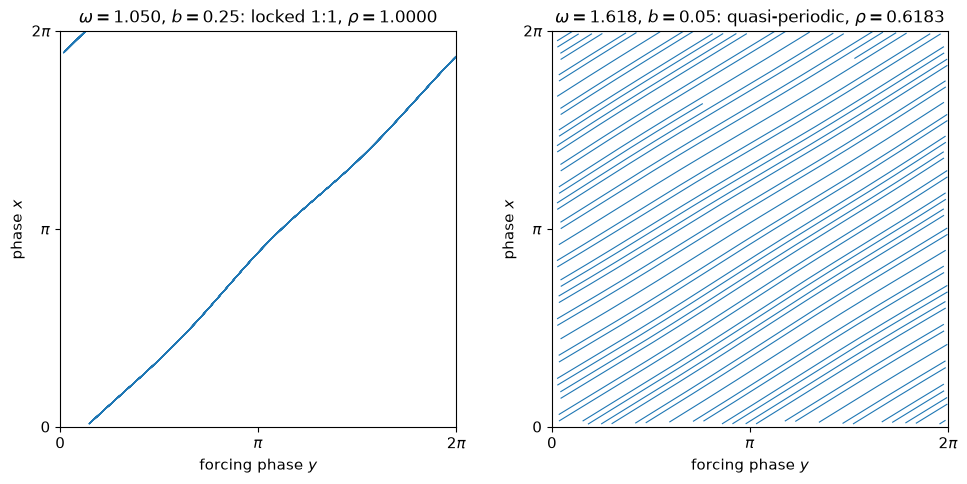

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.8))
for ax, (om, b, what) in zip(axs, [(1.05, 0.25, "locked 1:1"), ((1 + 5**0.5) / 2, 0.05, "quasi-periodic")]):
    tr = m.run(keep=False, om=om, b=b, total=250, trans=100)
    ax.plot(*broken(tr["y"], tr["x"]), lw=0.8, color="tab:blue")
    ax.set(xlim=(0, TWO_PI), ylim=(0, TWO_PI), aspect="equal", xlabel="forcing phase $y$", ylabel="phase $x$",
           title=rf"$\omega = {om:.3f}$, $b = {b}$: {what}, $\rho = {rotation_number(om, b):.4f}$")
    ax.set_xticks([0, np.pi, TWO_PI], ["$0$", r"$\pi$", r"$2\pi$"])
    ax.set_yticks([0, np.pi, TWO_PI], ["$0$", r"$\pi$", r"$2\pi$"])
fig.tight_layout()
fig.savefig(FIG / "torus_orbits.png")

### Devil's staircase at $b = 0.4$

$\rho$ against $\omega$ is a continuous, non-decreasing curve that is flat on
every locked interval (red for 1:1, 2:3, 1:2, 1:3). Without forcing it would be
$\rho = 1/\omega$ (dotted).

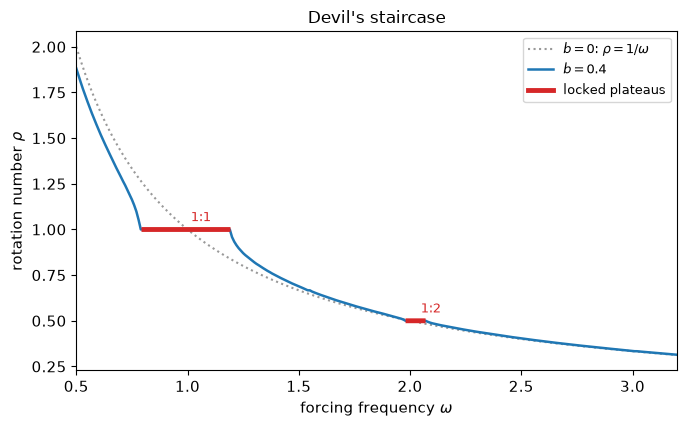

In [14]:
OM = np.linspace(0.5, 3.2, 271)
rho = np.array([rotation_number(o, 0.4) for o in OM])
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(OM, 1 / OM, color="0.6", ls=":", label=r"$b = 0$: $\rho = 1/\omega$")
ax.plot(OM, rho, color="tab:blue", lw=1.8, label="$b = 0.4$")
for frac in (Fraction(1, 1), Fraction(2, 3), Fraction(1, 2), Fraction(1, 3)):
    on = np.abs(rho - float(frac)) < 1e-5
    if on.any():
        ax.plot(OM[on], rho[on], color="tab:red", lw=3.5, solid_capstyle="butt")
        ax.annotate(f"{frac.numerator}:{frac.denominator}", (OM[on].mean(), float(frac)),
                    textcoords="offset points", xytext=(4, 6), color="tab:red", fontsize=9)
ax.plot([], [], color="tab:red", lw=3.5, label="locked plateaus")
ax.set(xlim=(0.5, 3.2), xlabel=r"forcing frequency $\omega$", ylabel=r"rotation number $\rho$",
       title="Devil's staircase")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "devils_staircase.png")

### Arnold tongues on an $(\omega, b)$ grid

Each grid point is coloured by its locked ratio (grey shade: unlocked, by
$\rho$). At $b = 0$ only $\omega = q/p$ exactly is locked: the tips of the
tongues.

Averaging to first order in $b$: the phase difference $\psi = x - y$ obeys
$\dot\psi = 1 - \omega + b\,H(\psi)$ with

$$
H(\psi) = \bigl\langle p(u)\cos(u - \psi) \bigr\rangle = -c\,\sin\psi, \qquad
c = \Bigl\langle \frac{\sin^2 u}{1 + a\cos u} \Bigr\rangle = \frac{1 - \sqrt{1 - a^2}}{a^2},
$$

so 1:1 locking needs $|\omega - 1| \le c\,b$: the dashed edges.

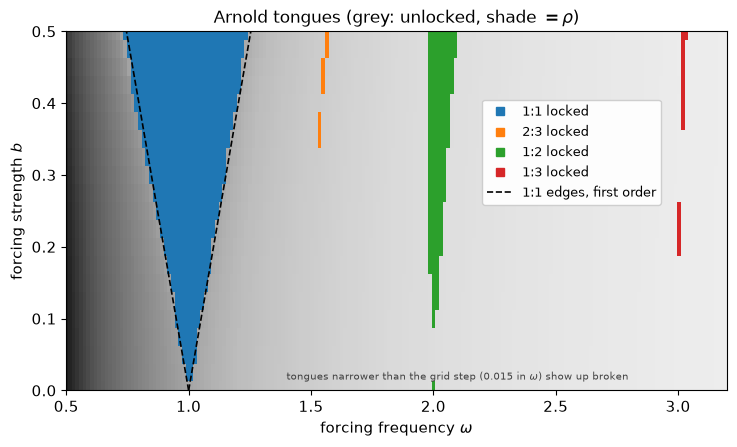

In [15]:
OMg, Bg = np.linspace(0.5, 3.2, 181), np.linspace(0, 0.5, 21)
R = np.array([[rotation_number(o, bb, cycles=120, skip=200) for o in OMg] for bb in Bg])
tongues = [Fraction(1, 1), Fraction(2, 3), Fraction(1, 2), Fraction(1, 3)]
locked = np.full(R.shape, np.nan)
for n, frac in enumerate(tongues):
    locked[np.abs(R - float(frac)) < 1e-5] = n
a = 0.25
c = (1 - np.sqrt(1 - a**2)) / a**2
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.pcolormesh(OMg, Bg, R, cmap="Greys", shading="nearest", vmin=0, vmax=2.2)
cmap = plt.get_cmap("tab10", 10)
ax.pcolormesh(OMg, Bg, locked, cmap=cmap, vmin=-0.5, vmax=9.5, shading="nearest")
for n, frac in enumerate(tongues):
    ax.plot([], [], "s", color=cmap(n), label=f"{frac.numerator}:{frac.denominator} locked")
bl = np.linspace(0, 0.5, 50)
ax.plot(1 - c * bl, bl, "k--", lw=1.2, label="1:1 edges, first order")
ax.plot(1 + c * bl, bl, "k--", lw=1.2)
ax.set(xlim=(0.5, 3.2), ylim=(0, 0.5), xlabel=r"forcing frequency $\omega$", ylabel="forcing strength $b$",
       title=r"Arnold tongues (grey: unlocked, shade $= \rho$)")
ax.text(1.4, 0.015, r"tongues narrower than the grid step (0.015 in $\omega$) show up broken",
        fontsize=7.5, color="0.25")
ax.legend(loc="lower left", bbox_to_anchor=(0.62, 0.5), framealpha=0.95)
fig.tight_layout()
fig.savefig(FIG / "arnold_tongues.png")

### Checks

* At $b = 0$, $x = t$ and $y = \omega t$ exactly, so $\rho = 1/\omega$
  (checked at $\omega = 1.3$ and $2.7$).
* At $b = 0.4$ the 1:1 plateau contains $\omega = 1$.
* The 1:1 tongue at $b = 0.05$: its edges, found by bisection from
  $\omega = 1$ outwards (with a long transient, since the approach to the
  locked orbit is slow near the edge), are $2cb$ apart to first order; the
  edges move by $O(b^2)$, so the relative error of the width is $O(b^2)$.

In [16]:
def tongue_edge(b, side):
    lo, hi = 1.0, 1 + side * 2 * c * b
    for _ in range(22):
        mid = (lo + hi) / 2
        locked = abs(rotation_number(mid, b, cycles=600, skip=300) - 1) < 1e-5
        lo, hi = (mid, hi) if locked else (lo, mid)
    return (lo + hi) / 2


check("rho at b = 0, om = 1.3 is 1/om (exact)", rotation_number(1.3, 0), 1 / 1.3, 1e-6)
check("rho at b = 0, om = 2.7 is 1/om (exact)", rotation_number(2.7, 0), 1 / 2.7, 1e-6)
plateau = OM[np.abs(rho - 1) < 1e-6]
check("1:1 plateau at b = 0.4 contains om = 1 (rho there)", rotation_number(1.0, 0.4), 1.0, 1e-6)
check("om = 1 lies inside the 1:1 plateau (1 = yes)", float(plateau.min() < 1 < plateau.max()), 1, 0)
bb = 0.05
width = tongue_edge(bb, +1) - tongue_edge(bb, -1)
check("1:1 tongue width / (2 c b) at b = 0.05 (averaging)", width / (2 * c * bb), 1.0, bb**2)
checks_done()

  ok   rho at b = 0, om = 1.3 is 1/om (exact): 0.769231 (expected 0.769231)


  ok   rho at b = 0, om = 2.7 is 1/om (exact): 0.37037 (expected 0.37037)


  ok   1:1 plateau at b = 0.4 contains om = 1 (rho there): 1 (expected 1)
  ok   om = 1 lies inside the 1:1 plateau (1 = yes): 1 (expected 1)


  ok   1:1 tongue width / (2 c b) at b = 0.05 (averaging): 1.00038 (expected 1)

21_forced-phase-oscillator: 5/5 checks passed


<a id="phase-oscillators-table"></a>
## 22. Two phase oscillators with a tabulated coupling

Two oscillators with phases $x_1, x_2$ and frequencies $\omega_1 = 1$,
$\omega_2$ (`w1`, `w2` in the code) interact through a function $h$:

$$
\dot x_1 = \omega_1 + a\,h(x_2 - x_1), \qquad \dot x_2 = \omega_2 + a\,h(x_1 - x_2),
$$

$$
h(t) = \sin t + 0.6 + 0.4\cos t + 0.2\sin 2t,
$$

with $a = 0.15$ and first $\omega_2 = 1.1$. $h$ is given to XPP as a table of
101 samples on $[0, 2\pi]$ (XPP's `table h % 101 0 2pi expr`, linearly
interpolated). The phase difference $\phi = x_2 - x_1$ obeys a single equation,

$$
\dot\phi = (\omega_2 - \omega_1) + a\,G(\phi), \qquad G(\phi) = h(-\phi) - h(\phi),
$$

so the pair locks ($\phi$ settles) exactly when
$|\omega_2 - \omega_1| \le a\max|G|$; outside that band $\phi$ drifts, slowly
near the edge.

We watch $\phi(t)$ inside and outside the band, compute the locking band and
the drift frequency from the tabulated $h$, and compare both with simulations.

In [17]:
section("22_phase-oscillators-table")

### The model

`PER` is the period used in the model (table range, `mod` and fold). `phi` is
an auxiliary output, $\phi = (x_2 - x_1) \bmod 2\pi$.

In [18]:
PER = 6.283185
H_EXPR = "sin(t)+.6+.4*cos(t)+.2*sin(2*t)"
mb = (ModelBuilder("phase_oscillators_table")
      .comment("two phase oscillators coupled through a tabulated function h")
      .table("h", n=101, lo=0, hi=PER, expr=H_EXPR)
      .ode("x1", "w1+a*h(mod(x2-x1,6.283185))")
      .ode("x2", "w2+a*h(mod(x1-x2,6.283185))")
      .aux("phi", "mod(x2-x1,6.283185)")
      .parameter(w1=1, w2=1.1, a=0.15)
      .initial(x1=0, x2=2)
      .option(fold="x1", tor_per=PER)
      .option(fold="x2")
      .option(total=200, dt=0.05))
print(mb.render())
m = mb.load(ODE)
w1 = 1.0

# two phase oscillators coupled through a tabulated function h
table h % 101 0 6.283185 sin(t)+.6+.4*cos(t)+.2*sin(2*t)
x1'=w1+a*h(mod(x2-x1,6.283185))
x2'=w2+a*h(mod(x1-x2,6.283185))
aux phi=mod(x2-x1,6.283185)
par w1=1,w2=1.1,a=0.15
init x1=0,x2=2
@ fold=x1,tor_per=6.283185
@ fold=x2
@ total=200,dt=0.05
done



Three helpers: `drift` unwraps $\phi$ and returns the times at which it has
gained each further full turn; `beat_frequency` is $2\pi$ over the mean time
per turn; `is_locked` says whether $\phi$ stays put after a transient.

In [19]:
def drift(tr):
    u = np.unwrap(tr["phi"], period=PER)
    k = np.floor((u - u[0]) / PER)
    i = np.where(np.diff(k) != 0)[0]
    t = tr.t
    tc = t[i] + (u[0] + PER * np.maximum(k[i], k[i + 1]) - u[i]) * (t[i + 1] - t[i]) / (u[i + 1] - u[i])
    return u, tc


def beat_frequency(w2, a, total=2000):
    _, tc = drift(m.run(keep=False, w2=w2, a=a, total=total, trans=200))
    return PER / np.diff(tc).mean() if len(tc) > 2 else 0.0


def is_locked(w2, a, total=2500):
    u, _ = drift(m.run(keep=False, w2=w2, a=a, total=total, trans=total / 5))
    return abs(u[-1] - u[0]) < 0.05

### $\phi$ against time

At $\omega_2 = 1.1$ the phase difference settles; at $1.3$ and $1.4$ it drifts,
lingering where $|\Delta + aG(\phi)|$ is small. The line is broken where
$\phi$ wraps.

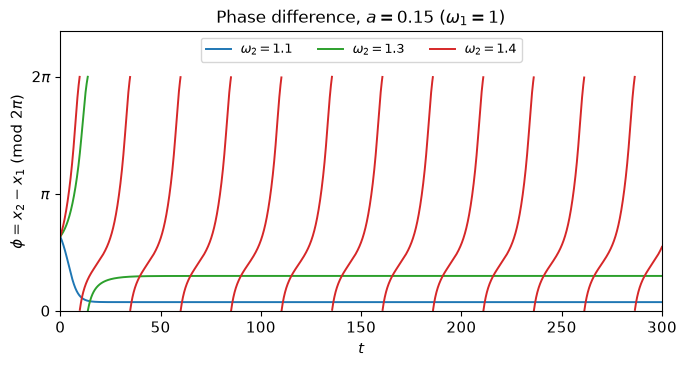

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for w2, col in ((1.1, "tab:blue"), (1.3, "tab:green"), (1.4, "tab:red")):
    tr = m.run(keep=False, w2=w2, total=300)
    p = tr["phi"].copy()
    p[1:][np.abs(np.diff(p)) > PER / 2] = np.nan
    ax.plot(tr.t, p, color=col, lw=1.4, label=rf"$\omega_2 = {w2}$")
ax.set(xlim=(0, 300), ylim=(0, 7.5), xlabel="$t$", ylabel=r"$\phi = x_2 - x_1$ (mod $2\pi$)",
       title=r"Phase difference, $a = 0.15$ ($\omega_1 = 1$)")
ax.set_yticks([0, np.pi, 2 * np.pi], ["$0$", r"$\pi$", r"$2\pi$"])
ax.legend(loc="upper center", ncol=3)
fig.tight_layout()
fig.savefig(FIG / "phase_difference.png")

### Theory from the tabulated $h$

$G$ is computed by linear interpolation of the same 101 samples XPP uses. With
$\Delta = \omega_2 - \omega_1$, the pair locks if $|\Delta| \le a\max|G|$;
otherwise $\phi$ makes one turn in time $\int_0^{2\pi} d\phi/|\Delta + aG(\phi)|$,
so the beat frequency is

$$
\Omega = \frac{2\pi}{\displaystyle\int_0^{2\pi} \frac{d\phi}{|\Delta + a\,G(\phi)|}} .
$$

In [21]:
tk = np.linspace(0, PER, 101)
hk = np.sin(tk) + .6 + .4 * np.cos(tk) + .2 * np.sin(2 * tk)


def G(p):
    h = lambda u: np.interp(np.mod(u, PER), tk, hk)
    return h(-p) - h(p)


grid = np.linspace(0, PER, 400001)[:-1]
Gmax = np.abs(G(grid)).max()


def beat_theory(delta, a):
    if abs(delta) <= a * Gmax:
        return 0.0
    return PER / (np.mean(1 / np.abs(delta + a * G(grid))) * PER)


print(f"max |G| from the table = {Gmax:.6f}: lock iff |w2 - w1| <= {Gmax:.4f} a")

max |G| from the table = 2.137227: lock iff |w2 - w1| <= 2.1372 a


### Beat frequency against $\omega_2$, and the locked region in $(\omega_2, a)$

Left: the simulated beat frequency on the theory curve, zero inside the band.
Right: a grid of simulations marked locked or not, against the edges
$|\omega_2 - \omega_1| = a\max|G|$.

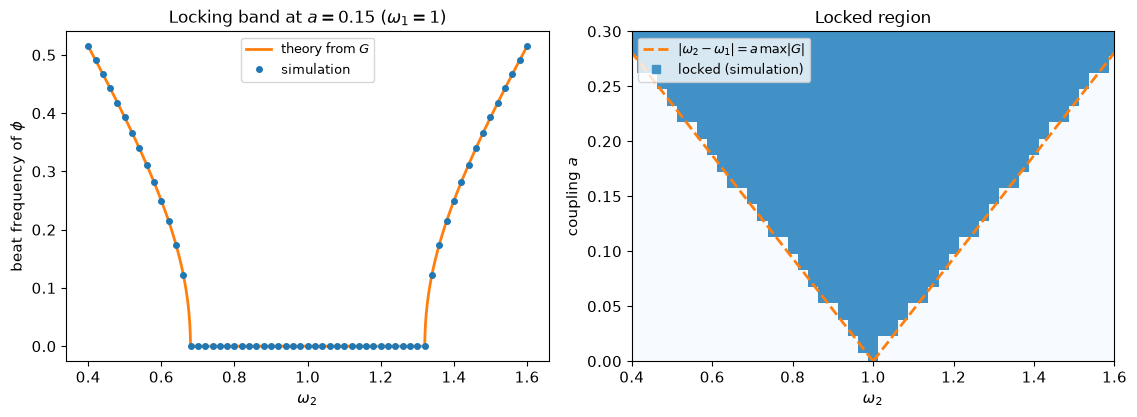

In [22]:
W2 = np.linspace(0.4, 1.6, 61)
sim = [beat_frequency(w, 0.15, total=1000) for w in W2]
fine = np.linspace(0.4, 1.6, 1201)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
a1.plot(fine, [beat_theory(w - w1, 0.15) for w in fine], color="tab:orange", lw=2, label="theory from $G$")
a1.plot(W2, sim, "o", color="tab:blue", ms=4, label="simulation")
a1.set(xlabel=r"$\omega_2$", ylabel=r"beat frequency of $\phi$", title=r"Locking band at $a = 0.15$ ($\omega_1 = 1$)")
a1.legend()
A, W2g = np.linspace(0, 0.3, 21), np.linspace(0.4, 1.6, 49)
L = np.array([[is_locked(w, aa, total=800) for w in W2g] for aa in A])
a2.pcolormesh(W2g, A, L, cmap="Blues", vmin=0, vmax=1.6, shading="nearest")
a2.plot(w1 + Gmax * A, A, "--", color="tab:orange", lw=2, label=r"$|\omega_2 - \omega_1| = a\,\max|G|$")
a2.plot(w1 - Gmax * A, A, "--", color="tab:orange", lw=2)
a2.plot([], [], "s", color=plt.get_cmap("Blues")(0.62), label="locked (simulation)")
a2.set(xlim=(0.4, 1.6), ylim=(0, 0.3), xlabel=r"$\omega_2$", ylabel="coupling $a$", title="Locked region")
a2.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "locking.png")

### Checks

* The locked phase at $\omega_2 = 1.1$, $a = 0.15$ solves
  $0.1 + 0.15\,G(\phi) = 0$ on the stable branch ($G' < 0$), near
  $\phi = 0.24$ (found by bisection).
* Both edges of the band at $a = 0.15$, $\omega_1 \pm a\max|G|$, found by
  bisection on `is_locked`.
* The beat frequency at $\omega_2 = 1.4$ against $\Omega$ above.
* The smooth $h$ gives $G(\phi) = -2\sin\phi - 0.4\sin 2\phi$, whose largest
  $|G|$ is at $\cos\phi = (-2 + \sqrt{9.12})/3.2$, where
  $|G| = 2\sin\phi + 0.8\sin\phi\cos\phi$. Linear interpolation on steps of
  $2\pi/100$ changes it by at most $\tfrac18(2\pi/100)^2\max|G''|$ with
  $\max|G''| \le 3.6$, about $1.8\times10^{-3}$.

In [23]:
lo, hi = 0.0, 1.0
for _ in range(60):
    lo, hi = ((lo + hi) / 2, hi) if 0.1 + 0.15 * G((lo + hi) / 2) > 0 else (lo, (lo + hi) / 2)


def edge(a, side):
    lo, hi = w1, w1 + side * 2 * a * Gmax
    for _ in range(20):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if is_locked(mid, a) else (lo, mid)
    return (lo + hi) / 2


check("locked phi at w2 = 1.1, a = 0.15 vs root of G", m.run(keep=False, total=400)["phi"][-1], lo, 1e-6)
check("upper edge of the band at a = 0.15", edge(0.15, +1), w1 + 0.15 * Gmax, 1e-4)
check("lower edge of the band at a = 0.15", edge(0.15, -1), w1 - 0.15 * Gmax, 1e-4)
check("beat frequency at w2 = 1.4, a = 0.15", beat_frequency(1.4, 0.15), beat_theory(0.4, 0.15), 1e-5)
cphi = (-2 + np.sqrt(9.12)) / 3.2
sphi = np.sqrt(1 - cphi**2)
check("max |G| of the table vs the smooth h", Gmax, 2 * sphi + 0.8 * sphi * cphi, (PER / 100) ** 2 / 8 * 3.6)
checks_done()

  ok   locked phi at w2 = 1.1, a = 0.15 vs root of G: 0.242574 (expected 0.242574)


  ok   upper edge of the band at a = 0.15: 1.32058 (expected 1.32058)


  ok   lower edge of the band at a = 0.15: 0.679416 (expected 0.679416)


  ok   beat frequency at w2 = 1.4, a = 0.15: 0.249738 (expected 0.249738)
  ok   max |G| of the table vs the smooth h: 2.13723 (expected 2.13738)

22_phase-oscillators-table: 5/5 checks passed


<a id="chirikov-taylor-map"></a>
## 23. Chirikov–Taylor (standard) map: invariant curves and chaos

A kicked rotor seen once per kick:

$$
p_{n+1} = p_n + K\sin q_n, \qquad q_{n+1} = q_n + p_{n+1}, \qquad \text{both modulo } 2\pi .
$$

The map preserves area. For $K = 0$ every horizontal line $p = \text{const}$
is invariant; as $K$ grows these curves break up, islands and chaotic layers
appear, and above $K_c = 0.9716$ (Greene 1979) the last curve that spans the
whole $q$ range is gone, so orbits can wander through all of $p$. (XPP
Studio's file writes the kick as $K\sin(q)/(2\pi)$, so its $K = 6$ is
$K = 0.955$ in the usual form used here.)

We draw phase portraits at $K = 0.5$, $0.9716$, $2$ and $6$, test transport in
$p$, find the fixed points $(0, 0)$ and $(\pi, 0)$ with their multipliers, and
show that the map preserves area.

In [24]:
section("23_chirikov-taylor-map")

### The model

`fixed("temp", ...)` is the new $p$, used by both lines of the map; `fold`
keeps $p$ and $q$ in $[0, 2\pi)$.

In [25]:
TWO_PI = 6.28318530718
mb = (ModelBuilder("chirikov_taylor_map")
      .comment("Chirikov-Taylor standard map on the torus")
      .fixed("temp", "p+K*sin(q)")
      .map("p", "temp")
      .map("q", "q+temp")
      .parameter(K=0.9716)
      .initial(p=4.1, q=1.2)
      .option(total=3000, meth="discrete", bound=1000)
      .option(fold="p", tor_per=TWO_PI)
      .option(fold="q"))
print(mb.render())
m = mb.load(ODE)

# Chirikov-Taylor standard map on the torus
temp=p+K*sin(q)
p(t+1)=temp
q(t+1)=q+temp
par K=0.9716
init p=4.1,q=1.2
@ total=3000,meth=discrete,bound=1000
@ fold=p,tor_per=6.28318530718
@ fold=q
done



### Phase portraits

32 orbits of 1500 iterates each, for four values of $K$. Then a transport
test: does one orbit from the chaotic layer near $p = 0$ reach every $p$
(share of 60 bins in $p$ visited by 100000 iterates)?

share of p in [0, 2pi) visited by one orbit from (0.01, 0.01): {0.5: np.float64(0.4666666666666667), 2.0: np.float64(1.0)}


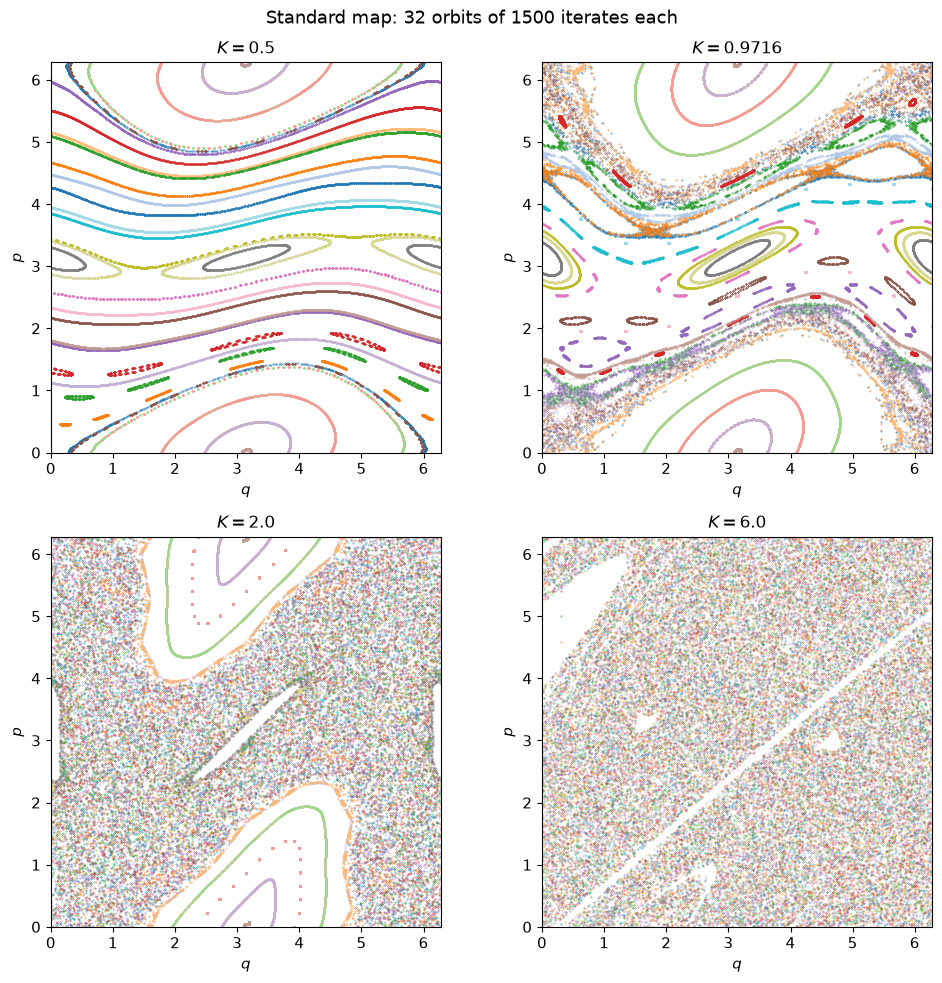

In [26]:
starts = [(q0, p0) for p0 in np.linspace(0.05, TWO_PI - 0.05, 16) for q0 in (0.3, np.pi)]
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for ax, K in zip(axs.flat, (0.5, 0.9716, 2.0, 6.0)):
    for k, (q0, p0) in enumerate(starts):
        tr = m.run(keep=False, K=K, q=q0, p=p0, total=1500)
        ax.plot(tr["q"], tr["p"], ".", ms=0.6, color=plt.cm.tab20(k % 20))
    ax.set(xlim=(0, TWO_PI), ylim=(0, TWO_PI), xlabel="$q$", ylabel="$p$", title=f"$K = {K}$")
    ax.set_aspect("equal")
fig.suptitle("Standard map: 32 orbits of 1500 iterates each")
fig.tight_layout()
fig.savefig(FIG / "phase_portraits.png")


def p_coverage(K):
    p = m.run(keep=False, K=K, q=0.01, p=0.01, total=100000)["p"]
    return np.mean(np.histogram(p, bins=60, range=(0, TWO_PI))[0] > 0)


cov = {K: p_coverage(K) for K in (0.5, 2.0)}
print(f"share of p in [0, 2pi) visited by one orbit from (0.01, 0.01): {cov}")

### Fixed points and multipliers

A fixed point needs $p_{n+1} = p_n$ and $q_n + p_{n+1} = q_n$ (mod $2\pi$):
$p = 0$ and $\sin q = 0$. The Jacobian in $(p, q)$ is

$$
J = \begin{pmatrix} 1 & K\cos q \\ 1 & 1 + K\cos q \end{pmatrix}, \qquad \det J = 1, \qquad \mathrm{tr}\,J = 2 + K\cos q .
$$

At $(0, 0)$ the trace is $2 + K > 2$: a saddle with multiplier
$1 + K/2 + \sqrt{(1 + K/2)^2 - 1}$. At $(\pi, 0)$ it is $2 - K$: for
$0 < K < 4$ the multipliers are $e^{\pm i\theta}$ with
$\cos\theta = 1 - K/2$ (elliptic), and at $K = 4$ one is $-1$.

XPP's Jacobian uses steps $\varepsilon\max(\varepsilon, |x|)$ with
$\varepsilon$ = `jac_eps`; at $p = 0$ that is $\varepsilon^2$, so
$\varepsilon = 10^{-4}$ (steps $10^{-8}$ in $p$, $3\times10^{-4}$ in $q$)
balances rounding and truncation errors.

In [27]:
m.set(newt_tol=1e-6, jac_eps=1e-4)
fp = {}
for K in (2.0, 3.9, 4.1):
    m.set(K=K)
    fp[K, "pi"] = m.equilibrium({"q": 3.0, "p": 0.05})
    fp[K, "0"] = m.equilibrium({"q": 0.05, "p": 0.05})
    print(f"K = {K}: (pi, 0) multipliers {np.round(fp[K, 'pi'].eigenvalues, 6)};"
          f" (0, 0) multipliers {np.round(fp[K, '0'].eigenvalues.real, 6)}")
m.set(K=0.9716)

K = 2.0: (pi, 0) multipliers [0.+1.j 0.-1.j]; (0, 0) multipliers [0.267949 3.732051]


K = 3.9: (pi, 0) multipliers [-0.95+0.31225j -0.95-0.31225j]; (0, 0) multipliers [0.174662 5.725338]


K = 4.1: (pi, 0) multipliers [-0.729844+0.j -1.370156+0.j]; (0, 0) multipliers [0.168594 5.931406]


<pyxpp.Model 23_chirikov-taylor-map.ode: vars=['P', 'Q'] aux=[] pars=1>

### Area preservation

Map a circle of 2000 starts (radius 0.2) and compare the areas enclosed before
and after (shoelace formula), after undoing the folding around the image of
the centre.

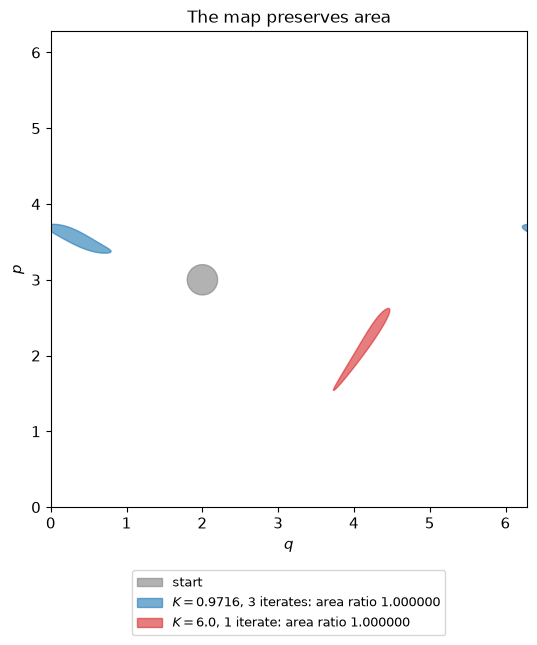

In [28]:
def shoelace(x, y):
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


th = np.linspace(0, 2 * np.pi, 2001)[:-1]
c, R = np.array([2.0, 3.0]), 0.2
Q0, P0 = c[0] + R * np.cos(th), c[1] + R * np.sin(th)
ratios = {}
fig, ax = plt.subplots(figsize=(5.5, 6.2))
ax.fill(Q0, P0, color="tab:gray", alpha=0.6, label="start")
for (K, n), col in zip([(0.9716, 3), (6.0, 1)], ("tab:blue", "tab:red")):
    img = np.array([[r["q"][-1], r["p"][-1]] for r in
                    (m.run(keep=False, K=K, q=q0, p=p0, total=n) for q0, p0 in zip(Q0, P0))])
    ctr = m.run(keep=False, K=K, q=c[0], p=c[1], total=n)
    ctr = np.array([ctr["q"][-1], ctr["p"][-1]])
    d = (img - ctr + np.pi) % TWO_PI - np.pi
    ratios[K, n] = shoelace(d[:, 0], d[:, 1]) / shoelace(Q0 - c[0], P0 - c[1])
    for sq in (-TWO_PI, 0, TWO_PI):
        ax.fill(ctr[0] + d[:, 0] + sq, ctr[1] + d[:, 1], color=col, alpha=0.6,
                label=f"$K = {K}$, {n} iterate{'s' * (n > 1)}: area ratio {ratios[K, n]:.6f}" if sq == 0 else None)
ax.set(xlim=(0, TWO_PI), ylim=(0, TWO_PI), xlabel="$q$", ylabel="$p$", title="The map preserves area")
ax.set_aspect("equal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
fig.savefig(FIG / "area.png", bbox_inches="tight")

### Checks

* The fixed point at $q = \pi$.
* At $K = 2$: the multipliers at $(\pi, 0)$ sum to $2 - K = 0$ and have
  modulus 1 (elliptic); the saddle multiplier at $(0, 0)$ is
  $1 + K/2 + \sqrt{(1 + K/2)^2 - 1} = 2 + \sqrt3$.
* At $K = 3.9$ the point $(\pi, 0)$ is still elliptic; at $K = 4.1$ it is a
  flip saddle with multipliers $-1.05 \pm \sqrt{1.05^2 - 1}$, the smaller
  being $-1.05 - \sqrt{0.1025}$.
* Area ratios equal to 1 (the polygon through 2000 points misses
  $O\bigl((2\pi/2000)^2\bigr) \approx 10^{-5}$ of the area of a smooth curve).
* Transport: at $K = 2 > K_c$ one orbit visits all of $p$; at
  $K = 0.5 < K_c$ invariant curves block it.

In [29]:
check("fixed point q = pi (exact)", fp[2.0, "pi"].x["Q"], np.pi, 1e-9)
check("K = 2: (pi, 0) multipliers sum to 2 - K = 0 (exact)", fp[2.0, "pi"].eigenvalues.sum().real, 0, 1e-6)
check("K = 2: |multiplier| at (pi, 0) = 1 (elliptic, exact)", abs(fp[2.0, "pi"].eigenvalues[0]), 1, 1e-6)
check("K = 2: saddle multiplier at (0, 0), 2 + sqrt(3) (exact)", fp[2.0, "0"].eigenvalues.real.max(),
      2 + np.sqrt(3), 1e-6)
check("K = 3.9: |multiplier| at (pi, 0) still 1 (exact)", abs(fp[3.9, "pi"].eigenvalues[0]), 1, 1e-6)
check("K = 4.1: (pi, 0) a flip saddle, -1.05 - sqrt(0.1025) (exact)",
      fp[4.1, "pi"].eigenvalues.real.min(), -1.05 - np.sqrt(0.1025), 1e-6)
check("area ratio after 3 iterates, K = 0.9716 (exact 1)", ratios[0.9716, 3], 1, 1e-5)
check("area ratio after 1 iterate, K = 6 (exact 1)", ratios[6.0, 1], 1, 1e-5)
check("K = 2 (> 0.9716): one orbit visits all p (share 1)", cov[2.0], 1, 0)
check("K = 0.5 (< 0.9716): invariant curves block it (1 = blocked)", float(cov[0.5] < 1), 1, 0)
checks_done()

  ok   fixed point q = pi (exact): 3.14159 (expected 3.14159)
  ok   K = 2: (pi, 0) multipliers sum to 2 - K = 0 (exact): 3.28978e-08 (expected 0)
  ok   K = 2: |multiplier| at (pi, 0) = 1 (elliptic, exact): 1 (expected 1)
  ok   K = 2: saddle multiplier at (0, 0), 2 + sqrt(3) (exact): 3.73205 (expected 3.73205)
  ok   K = 3.9: |multiplier| at (pi, 0) still 1 (exact): 1 (expected 1)
  ok   K = 4.1: (pi, 0) a flip saddle, -1.05 - sqrt(0.1025) (exact): -1.37016 (expected -1.37016)
  ok   area ratio after 3 iterates, K = 0.9716 (exact 1): 1 (expected 1)
  ok   area ratio after 1 iterate, K = 6 (exact 1): 1 (expected 1)
  ok   K = 2 (> 0.9716): one orbit visits all p (share 1): 1 (expected 1)
  ok   K = 0.5 (< 0.9716): invariant curves block it (1 = blocked): 1 (expected 1)

23_chirikov-taylor-map: 10/10 checks passed


<a id="piecewise-affine-map"></a>
## 24. A piecewise affine map of the unit square

From Ashwin and Goetz (SIADS 2006):

$$
x_{n+1} = y_n, \qquad y_{n+1} = (-x_n + a\,y_n) - \lfloor -x_n + a\,y_n \rfloor ,
$$

i.e. $y_{n+1}$ is the fractional part of $-x_n + a y_n$. Away from the lines
where $-x + ay$ crosses an integer, the map is the linear map

$$
M = \begin{pmatrix} 0 & 1 \\ -1 & a \end{pmatrix}
$$

plus an integer shift: $\det M = 1$, so it preserves area, and for $|a| < 2$
it is a rotation in disguise (eigenvalues $e^{\pm i\theta}$ with
$\cos\theta = a/2$). The cutting by the fractional part makes a rich mixture of
periodic islands and complicated, fractal sets of orbits. (XPP Studio's file
uses `floor`; XPP's own name for it is `flr`, used here.)

We draw long orbits for several $a$, check that the map stays in the square,
can be undone exactly and preserves area, and find the periods of many starts,
including a grid of starts at the golden mean $a = (\sqrt5 - 1)/2 = 2\cos(2\pi/5)$.

In [30]:
section("24_piecewise-affine-map")

### The model

`mod1_dist` is the distance on a circle of length 1 (values just below 1 and
just above 0 are close).

In [31]:
mb = (ModelBuilder("piecewise_affine_map")
      .comment("piecewise affine map on the unit square (Ashwin & Goetz 2006)")
      .parameter(a=0.5)
      .fixed("yy", "-x+a*y")
      .fixed("ny", "yy-flr(yy)")
      .map("x", "y")
      .map("y", "ny")
      .initial(x=0.4319130445, y=0.2635796134)
      .option(maxstor=40000, meth="discrete", total=30000, bound=10000))
print(mb.render())
m = mb.load(ODE)
GOLD = (np.sqrt(5) - 1) / 2


def mod1_dist(u, v):
    d = np.abs(u - v) % 1
    return np.minimum(d, 1 - d)

# piecewise affine map on the unit square (Ashwin & Goetz 2006)
par a=0.5
yy=-x+a*y
ny=yy-flr(yy)
x(t+1)=y
y(t+1)=ny
init x=0.4319130445,y=0.2635796134
@ maxstor=40000,meth=discrete,total=30000,bound=10000
done



### Long orbits

30000 iterates from XPP Studio's start for four values of $a$. On the way we
check the inverse map: $y_n = x_{n+1}$, and $x_n = \{a\,x_{n+1} - y_{n+1}\}$
(fractional part) since $x_n \in [0, 1)$. At the golden mean this start has
period 10, so 40 random starts are added.

orbits stay in the unit square: True; largest error of the inverse map 7.15e-08


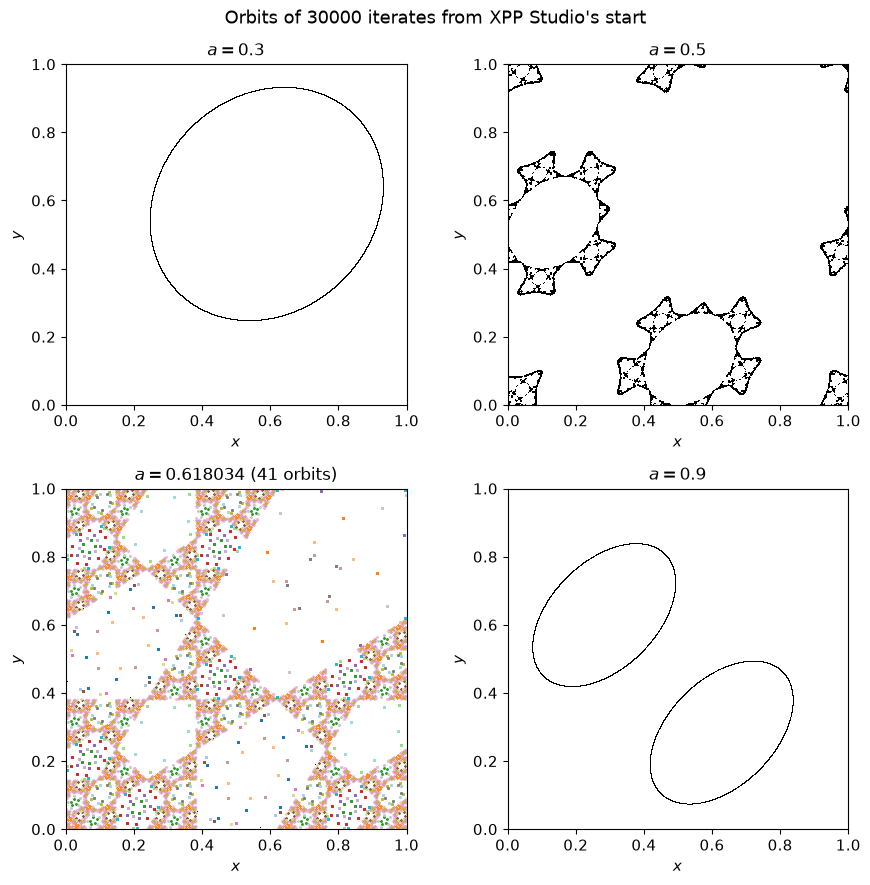

In [32]:
fig, axs = plt.subplots(2, 2, figsize=(9, 9))
in_square, inv_err = True, 0.0
for ax, a in zip(axs.flat, (0.3, 0.5, GOLD, 0.9)):
    tr = m.run(keep=False, a=a)
    x, y = tr["x"], tr["y"]
    in_square &= bool(x.min() >= 0 and x.max() < 1 and y.min() >= 0 and y.max() < 1)
    inv_err = max(inv_err, mod1_dist((a * x[1:] - y[1:]) % 1, x[:-1]).max())
    ax.plot(x, y, ",k")
    title = f"$a = {a:.6g}$"
    if a == GOLD:
        for k, (x0, y0) in enumerate(np.random.default_rng(0).random((40, 2))):
            o = m.run(keep=False, a=a, x=x0, y=y0, total=3000)
            ax.plot(o["x"], o["y"], ".", ms=0.5, color=plt.cm.tab20(k % 20))
        title += " (41 orbits)"
    ax.set(xlim=(0, 1), ylim=(0, 1), title=title, xlabel="$x$", ylabel="$y$")
    ax.set_aspect("equal")
fig.suptitle("Orbits of 30000 iterates from XPP Studio's start")
fig.tight_layout()
fig.savefig(FIG / "orbits.png", dpi=150)
print(f"orbits stay in the unit square: {in_square}; largest error of the inverse map {inv_err:.2e}")

### Area

A square of starts on which $-x + ay$ stays in $(0, 1)$, mapped once: there
the map is affine, so the image is exactly a parallelogram of the same area.

In [33]:
def shoelace(x, y):
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))


sq = np.array([[0.1, 0.5], [0.3, 0.5], [0.3, 0.7], [0.1, 0.7]])
img = np.array([[r["x"][-1], r["y"][-1]] for r in
                (m.run(keep=False, a=GOLD, x=x0, y=y0, total=1) for x0, y0 in sq)])
area_ratio = shoelace(*img.T) / shoelace(*sq.T)
print(f"area of a square after one iterate / before: {area_ratio:.8f}")

area of a square after one iterate / before: 0.99999991


### Periods

`periods` returns, for each start $z$, the smallest $p$ up to `n_iter` with
$F^p(z) = z$ (0 if none is found). We use 200 random starts at $a = 0$ and at
$a = 1$, and a $150 \times 150$ grid of starts at the golden mean, coloured by
period (red: no period up to 1200).

a = 0: periods [4]; a = 1: periods [6]
a = golden: periods found [5, 10, 15, 35, 65, 75, 135, 265, 535, 565, 1065]; 8.5% of starts not periodic within 1200


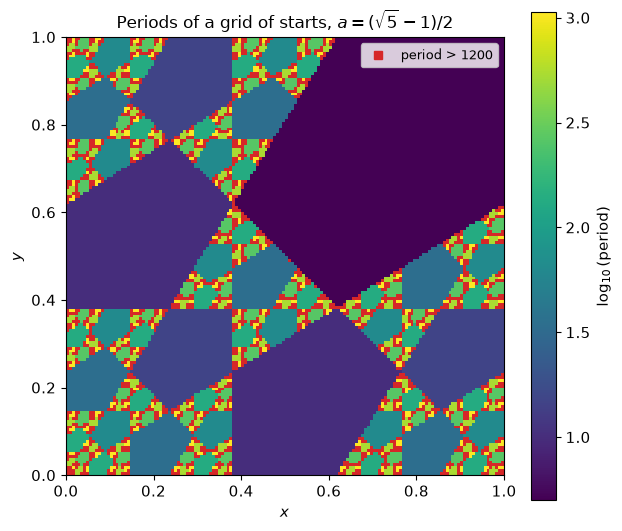

In [34]:
rng = np.random.default_rng(1)


def periods(a, pts, n_iter):
    out = []
    for x0, y0 in pts:
        tr = m.run(keep=False, a=a, x=x0, y=y0, total=n_iter)
        hit = np.where((mod1_dist(tr["x"][1:], tr["x"][0]) < 1e-5) &
                       (mod1_dist(tr["y"][1:], tr["y"][0]) < 1e-5))[0]
        out.append(hit[0] + 1 if len(hit) else 0)
    return np.array(out)


per0, per1 = periods(0.0, rng.random((200, 2)), 50), periods(1.0, rng.random((200, 2)), 50)
g = (np.arange(150) + 0.5) / 150
pts = np.array([(x0, y0) for y0 in g for x0 in g])
perg = periods(GOLD, pts, 1200)
found = perg[perg > 0]
print(f"a = 0: periods {sorted(int(p) for p in set(per0))}; a = 1: periods {sorted(int(p) for p in set(per1))}")
print(f"a = golden: periods found {sorted(int(p) for p in set(found))}; {np.mean(perg == 0):.1%} of starts not periodic within 1200")

fig, ax = plt.subplots(figsize=(6.4, 5.6))
img = np.where(perg > 0, np.log10(np.maximum(perg, 1)), np.nan).reshape(150, 150)
cmap = plt.cm.viridis.copy()
cmap.set_bad("tab:red")
sc = ax.imshow(img, origin="lower", extent=(0, 1, 0, 1), cmap=cmap, interpolation="nearest")
ax.plot([], [], "s", color="tab:red", label="period > 1200")
cb = fig.colorbar(sc, ax=ax)
cb.set_label(r"$\log_{10}$(period)")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="$x$", ylabel="$y$",
       title=r"Periods of a grid of starts, $a = (\sqrt{5} - 1)/2$")
ax.set_aspect("equal")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "periods_golden.png", dpi=150)

### Checks

* Orbits stay in $[0, 1)^2$, and the inverse map reproduces them. XPP stores
  orbits in single precision (about $10^{-7}$), hence tolerances of $10^{-6}$.
* The area ratio of the square is $\det M = 1$. Each stored corner is off by up
  to $2^{-24}$ per coordinate, so the area by about (perimeter)$\times 2^{-24}$;
  relative to an area of 0.04 that allows about $1.2\times10^{-6}$, and the
  tolerance is 4 times that.
* $a = 0$: $M$ is an integer matrix with $M^4 = I$, so $F^4(z) = z + \text{integer} = z$:
  every start has period 4.
* $a = 1$: $M$ is an integer matrix with $M^6 = I$, so $F^6$ is the identity.
* $a = 2\cos(2\pi/5)$: on a periodic island $F^p$ is $M^p$ plus a shift, which
  fixes an open set only if $M^p = I$, i.e. $p$ is a multiple of 5.

In [35]:
check("orbits stay in [0, 1)^2 (1 = yes)", float(in_square), 1, 0)
check("the inverse map reproduces the orbit, largest error (exact 0)", inv_err, 0, 1e-6)
check("area ratio of a square, det M = 1 (exact)", area_ratio, 1, 5e-6)
check("a = 0: share of starts with period 4 (exact 1)", np.mean(per0 == 4), 1, 0)
check("a = 1: share of starts with period 6 (exact 1)", np.mean(per1 == 6), 1, 0)
check("a = golden: share of periods that are multiples of 5 (exact 1)", np.mean(found % 5 == 0), 1, 0)
checks_done()

  ok   orbits stay in [0, 1)^2 (1 = yes): 1 (expected 1)
  ok   the inverse map reproduces the orbit, largest error (exact 0): 7.15256e-08 (expected 0)
  ok   area ratio of a square, det M = 1 (exact): 1 (expected 1)
  ok   a = 0: share of starts with period 4 (exact 1): 1 (expected 1)
  ok   a = 1: share of starts with period 6 (exact 1): 1 (expected 1)
  ok   a = golden: share of periods that are multiples of 5 (exact 1): 1 (expected 1)

24_piecewise-affine-map: 6/6 checks passed


<a id="coupled-ginzburg-landau"></a>
## 25. Ginzburg–Landau oscillator: phase reduction

The complex Ginzburg–Landau ($\lambda$–$\omega$) oscillator in real
coordinates, as in Wilson & Ermentrout, Phys. Rev. Lett. 123, 164101 (2019):

$$
\dot x = x\,(1 - r^2) - q\,r^2 y, \qquad \dot y = y\,(1 - r^2) + q\,r^2 x, \qquad r^2 = x^2 + y^2,
$$

with $q = 1$ (and later $q = 1.5$) and coupling parameter $d = 0.9$. In polar
form $\dot r = r(1 - r^2)$, $\dot\theta = q r^2$: the limit cycle is the unit
circle, traversed as $(\cos qt, \sin qt)$ with period $2\pi/q$. Its phase
response (adjoint), its isostable rate and the interaction function $H$ for
the coupling used in the paper are all known exactly, which makes it a good
test of XPP's phase reduction tools (*nUmerics → Averaging*, with the
second-order reduction added in XPPAUT 8.1).

We find one period, compute the adjoint and $H$ with XPP for $q = 1$ and
$q = 1.5$, run the second-order reduction ($H_2$ and $\gamma$), and compare
everything with the exact formulas.

In [36]:
section("25_coupled-ginzburg-landau")

### The model and the exact results

`A` is XPP's *nUmerics → Averaging* menu.

The phase $\varphi = \theta + q\ln r$ advances at the constant rate $q$
($\dot\varphi = q r^2 + q\,\dot r/r = q$), so its level sets are the
isochrons. On $r = 1$, $\nabla\theta = (-\sin, \cos)$ and
$\nabla r = (\cos, \sin)$; XPP normalises the adjoint so that
$Z\cdot F = 1$ (phase measured in time), i.e. $Z = \nabla\varphi/q$:

$$
Z(t) = \frac{1}{q}\bigl(q\cos qt - \sin qt,\; \cos qt + q\sin qt\bigr).
$$

In complex form $Z = (q + i)\,e^{iqt}/q$, and the coupling is
$G = (1 + id)(z' - z)$ with $z' = e^{iq(t+s)}$, so
$Z\cdot G = \mathrm{Re}\bigl[\bar Z G\bigr] = \mathrm{Re}\bigl[(q - i)(1 + id)(e^{iqs} - 1)\bigr]/q$
does not depend on $t$, and

$$
H(s) = \frac{(q + d)(\cos qs - 1) - (qd - 1)\sin qs}{q} .
$$

In [37]:
import re

mb = (ModelBuilder("ginzburg_landau")
      .comment("complex Ginzburg-Landau oscillator in real coordinates")
      .ode("x", "x*(1-x^2-y^2)-q*(x^2+y^2)*y")
      .ode("y", "y*(1-x^2-y^2)+q*(x^2+y^2)*x")
      .parameter(q=1, d=0.9)
      .initial(x=1, y=0)
      .option(total=40, dt=0.01, meth="rk4"))
print(mb.render())
m = mb.load(ODE)
d = 0.9
A = m.buttons.numerics.averaging


def Z_exact(t, q):
    return (q * np.cos(q * t) - np.sin(q * t)) / q, (np.cos(q * t) + q * np.sin(q * t)) / q


def H_exact(s, q):
    return ((q + d) * (np.cos(q * s) - 1) - (q * d - 1) * np.sin(q * s)) / q

# complex Ginzburg-Landau oscillator in real coordinates
x'=x*(1-x^2-y^2)-q*(x^2+y^2)*y
y'=y*(1-x^2-y^2)+q*(x^2+y^2)*x
par q=1,d=0.9
init x=1,y=0
@ total=40,dt=0.01,meth=rungekutta
done



### One period, the adjoint and $H$, for two values of $q$

For each $q$: a run, then *Initialconds → Periodic* finds one period (the
orbit then starts at the maximum of $x$, i.e. $\theta = 0$). *New adjoint*
puts the adjoint in the data (columns $t$, $Z_x$, $Z_y$), *Make H* computes
$H$ for the coupling $\bigl((x' - x) - d(y' - y),\ (y' - y) + d(x' - x)\bigr)$
(the first column after $t$ is $H$), and *Orbit* puts the orbit back in the
data browser.

In [38]:
res = {}
for q in (1.0, 1.5):
    m.set(q=q, x=1, y=0, total=50, trans=0)
    m.run()
    m.buttons.initialconds.periodic()
    T = m.numerics["total"]
    n = len(m.log)
    A.new_adj()
    adj = m.data
    log_adj = m.log[n:]
    A.make_h("(x'-x)-d*(y'-y)", "(y'-y)+d*(x'-x)")
    H = m.data
    A.orbit()
    res[q] = dict(T=T, adj=adj, H=H, log=log_adj)
    print(f"q = {q}: period {T:.10f} (exact 2*pi/q = {2 * np.pi / q:.10f})")
    print("  XPP:", log_adj.strip().splitlines()[0].strip())

q = 1.0: period 6.2831853072 (exact 2*pi/q = 6.2831853072)
  XPP: Adjoint of the cycle: period 6.28318530738 (grid of 800 steps), Z.f = 1 to 1.9e-09, Z periodic to 1.9e-09


q = 1.5: period 4.1887902048 (exact 2*pi/q = 4.1887902048)
  XPP: Adjoint of the cycle: period 4.18879020492 (grid of 800 steps), Z.f = 1 to 9.2e-10, Z periodic to 9.2e-10


XPP's adjoint (dashed) on the exact one (wide, pale) for both $q$, and $H$ at
$q = 1$.

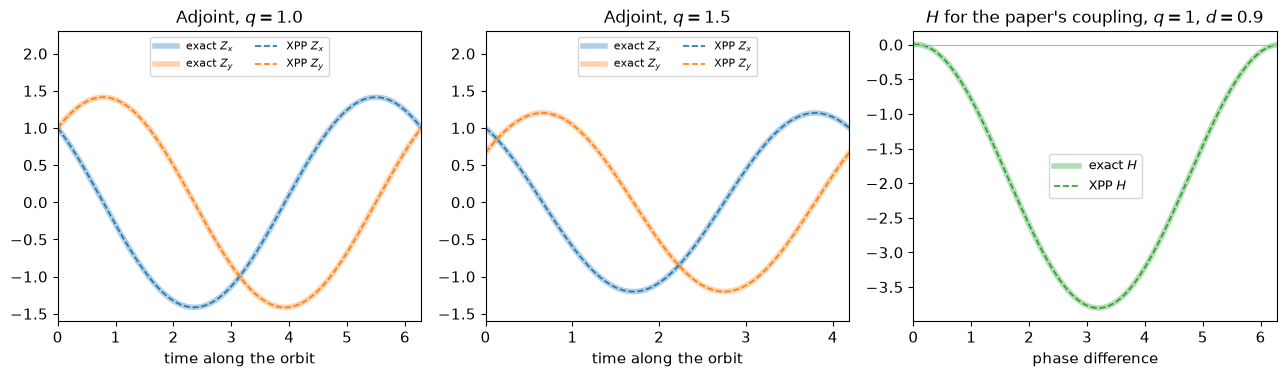

In [39]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, q in zip(axs[:2], (1.0, 1.5)):
    adj = res[q]["adj"]
    zx, zy = Z_exact(adj.t, q)
    ax.plot(adj.t, zx, color="tab:blue", lw=4, alpha=0.35, label="exact $Z_x$")
    ax.plot(adj.t, zy, color="tab:orange", lw=4, alpha=0.35, label="exact $Z_y$")
    ax.plot(adj.t, adj["x"], color="tab:blue", lw=1.2, ls="--", label="XPP $Z_x$")
    ax.plot(adj.t, adj["y"], color="tab:orange", lw=1.2, ls="--", label="XPP $Z_y$")
    ax.set(xlim=(0, res[q]["T"]), ylim=(-1.6, 2.3), xlabel="time along the orbit", title=f"Adjoint, $q = {q}$")
    ax.legend(fontsize=8, ncol=2, loc="upper center")
H = res[1.0]["H"]
axs[2].plot(H.t, H_exact(H.t, 1.0), color="tab:green", lw=4, alpha=0.35, label="exact $H$")
axs[2].plot(H.t, H["x"], color="tab:green", lw=1.2, ls="--", label="XPP $H$")
axs[2].axhline(0, color="0.7", lw=0.8)
axs[2].set(xlim=(0, res[1.0]["T"]), xlabel="phase difference",
           title=f"$H$ for the paper's coupling, $q = 1$, $d = {d}$")
axs[2].legend(loc="center")
fig.tight_layout()
fig.savefig(FIG / "adjoint_and_H.png")

### Second order: $H_2$ and $\gamma$, at $q = 1$

XPP's second-order phase reduction (*Averaging → H2*) needs the orbit, the
adjoint and $H$ first; it reports its results in the log, from which we read
$\gamma$.

In [40]:
m.set(q=1.0, x=1, y=0, total=50, trans=0)
m.run()
m.buttons.initialconds.periodic()
A.new_adj()
A.make_h("(x'-x)-d*(y'-y)", "(y'-y)+d*(x'-x)")
A.orbit()
n = len(m.log)
A.h2()
log_h2 = m.log[n:]
print("XPP, second-order phase reduction (q = 1, d = 0.9):")
print("\n".join("  " + line.strip() for line in log_h2.strip().splitlines()))
gamma = float(re.search(r"gamma = .*?= *([-+0-9.eE]+)", log_h2).group(1))
print(f"  gamma = {gamma}")

XPP, second-order phase reduction (q = 1, d = 0.9):
  H2 computed (two coupled cells, second order): H2(0)=0, max |H2|=2.1105549
  g2+g3 = -2 odd(H2); gamma = (g2'(0)+g3'(0))/4 = -0.81 (from A: -0.81, from Bf: -0.81)
  gamma = -0.81


### Checks

* The period $2\pi/q$ for $q = 1$ and $1.5$.
* The adjoint against $Z(t)$ and $H$ against $H(s)$ above, for both $q$
  (largest difference over the period).
* The mean of $H$ over a period: $-(q + d)/q$, i.e. $-1.9$ at $q = 1$.
* The isostable (Floquet) exponent: $\dot r = r(1 - r^2)$ gives
  $\delta\dot r = (1 - 3r^2)\,\delta r = -2\,\delta r$ on $r = 1$, for any $q$,
  so $\kappa = -2$ (read from XPP's log at $q = 1.5$).

In [41]:
for q in (1.0, 1.5):
    check(f"period at q = {q} vs 2*pi/q (exact)", res[q]["T"], 2 * np.pi / q, 1e-8)
for q in (1.0, 1.5):
    adj = res[q]["adj"]
    zx, zy = Z_exact(adj.t, q)
    err = max(np.abs(adj["x"] - zx).max(), np.abs(adj["y"] - zy).max())
    check(f"adjoint at q = {q}: max |XPP - exact|", err, 0, 1e-5)
for q in (1.0, 1.5):
    H = res[q]["H"]
    check(f"H at q = {q}: max |XPP - exact|", np.abs(H["x"] - H_exact(H.t, q)).max(), 0, 1e-5)
check("mean of H at q = 1 is -(q + d)/q (exact)", res[1.0]["H"]["x"][:-1].mean(), -(1 + d), 1e-5)
kappa = float(re.search(r"kappa = ([-+0-9.eE]+)", res[1.5]["log"]).group(1))
check("isostable rate kappa at q = 1.5 (exact -2)", kappa, -2.0, 1e-6)
checks_done()

  ok   period at q = 1.0 vs 2*pi/q (exact): 6.28319 (expected 6.28319)
  ok   period at q = 1.5 vs 2*pi/q (exact): 4.18879 (expected 4.18879)
  ok   adjoint at q = 1.0: max |XPP - exact|: 3.33078e-07 (expected 0)
  ok   adjoint at q = 1.5: max |XPP - exact|: 3.9795e-07 (expected 0)
  ok   H at q = 1.0: max |XPP - exact|: 4.26031e-07 (expected 0)
  ok   H at q = 1.5: max |XPP - exact|: 3.34155e-07 (expected 0)
  ok   mean of H at q = 1 is -(q + d)/q (exact): -1.9 (expected -1.9)
  ok   isostable rate kappa at q = 1.5 (exact -2): -2 (expected -2)

25_coupled-ginzburg-landau: 8/8 checks passed


## Summary

All checks of this notebook:

In [42]:
for name, r in results.items():
    print(f"{name:40s} {sum(r):3d}/{len(r)}")
n_ok = sum(sum(r) for r in results.values())
n = sum(len(r) for r in results.values())
print(f"\n{n_ok}/{n} checks passed")

20_forced-duffing                          6/6
21_forced-phase-oscillator                 5/5
22_phase-oscillators-table                 5/5
23_chirikov-taylor-map                    10/10
24_piecewise-affine-map                    6/6
25_coupled-ginzburg-landau                 8/8

40/40 checks passed
